# Manuscript table reproduction and scope

This notebook uses the **latest supplied manuscript**: *Simulating closed- and open-system dynamics of Tavis–Cummings lattices on fault-tolerant quantum computers*. It reproduces Tables II and VI from complete coherent circuit decompositions, Tables III/IV as explicitly labelled arithmetic primitive audits, and the worked per-channel counts of Appendix H. A Table VII-style open-family extension is also supplied.

Table III uses measurement-assisted primitive conventions and fixed b=B=20; Tables II, VI and Appendix H use fully coherent circuits and precision derived from an accuracy target. Their totals are not interchangeable. Arithmetic DEST slack is reported, not inserted into circuits to force agreement. No independent arithmetic-ledger Python script is required.

Figure 7 is reproduced from a separately generated 60-row resource table covering its full parameter sweep.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
os.environ.setdefault('MPLCONFIGDIR','/tmp/tcl-mpl')
os.environ.setdefault('NUMBA_CACHE_DIR','/tmp/tcl-numba')
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'resource_estimation/gqsp.py').is_file())
sys.path.insert(0,str(ROOT/'resource_estimation'))
sys.path.insert(0,str(ROOT/'validation'))
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
import gqsp as resources
import validation as validate


In [2]:
tables=resources.manuscript_tables()
print('All tables generated using only the three consolidated resource modules.')


All tables generated using only the three consolidated resource modules.


## Table II: complete coherent encodings and shared controlled walks

In [3]:
display(tables['II'])
display(pd.read_csv(resources.RESULTS/'table_II_differences.csv'))


,L,N,n_max,b,B,a,cU_direct,cU_row,cW_direct,cW_row,cW_pair,saving_percent,P_ph,Q_direct,Q_pair
0,16,1,3,20,19,108,2308,2496,3690,4066,3874,4.749613,32,297,329
1,64,2,7,23,22,128,8834,10046,14410,16834,15682,8.111210,192,613,805
2,256,4,15,27,26,154,52212,58864,83720,97024,90880,7.878521,1024,2399,3423


,L,N,n_max,b,B,a,cU_direct,cU_row,cW_direct,cW_row,cW_pair,saving_percent,P_ph,Q_direct,Q_pair
0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0


## Figure 7: controlled-walk resources from the generated table

The three Table II instances alone do not span Figure 7. We therefore generate the full sweep: **4x4, 4x8, 8x8, 8x16, 16x16**, each at **N=2** and cutoffs **3, 7, 15, 31**, for direct, paired and independent-row implementations. This produces 60 measured rows from complete executable shared-walk decompositions.

The planner derives b and B for each instance at $|\tau|=1$, $\epsilon_{\rm sim}=10^{-3}$, $t=0.05$, $g=\nu=1$, $\Delta=0$, after removing the uniform potential. The horizontal coordinate includes the occupation phase-gradient catalyst and the verified reusable clean workspace. The vertical coordinate is the ordinary coherent Toffoli count per controlled walk. Outer/GQSP rotation synthesis and catalyst preparation are excluded.

**Every plotted coordinate is read from `results/figure7_resource_table.csv`.** The parameter grid is specified explicitly; resource values are never transcribed from the figure or inserted as constants.

The previously validated complete-bundle Qualtran table is reused here, with its source hashes recorded. All 60 Toffoli/qubit pairs were independently regenerated with the consolidated code and agree exactly. By default the notebook reads the saved checksum-verified table; set `RECOMPILE_FIGURE7=True` to force fresh circuit counts.

,Lx,Ly,N,n_max,mode,b,B,coherent_ccx,peak_logical_qubits
0,4,4,2,3,direct,20,19,3878,312
1,4,4,2,3,paired,20,19,4062,344
2,4,4,2,3,sparse,20,19,4254,344
3,4,4,2,7,direct,21,20,4474,340
4,4,4,2,7,paired,21,20,4786,388
5,4,4,2,7,sparse,21,20,5074,388
6,4,4,2,15,direct,22,21,6200,372
7,4,4,2,15,paired,22,21,6640,436
8,4,4,2,15,sparse,22,21,7024,436
9,4,4,2,31,direct,23,22,7084,400


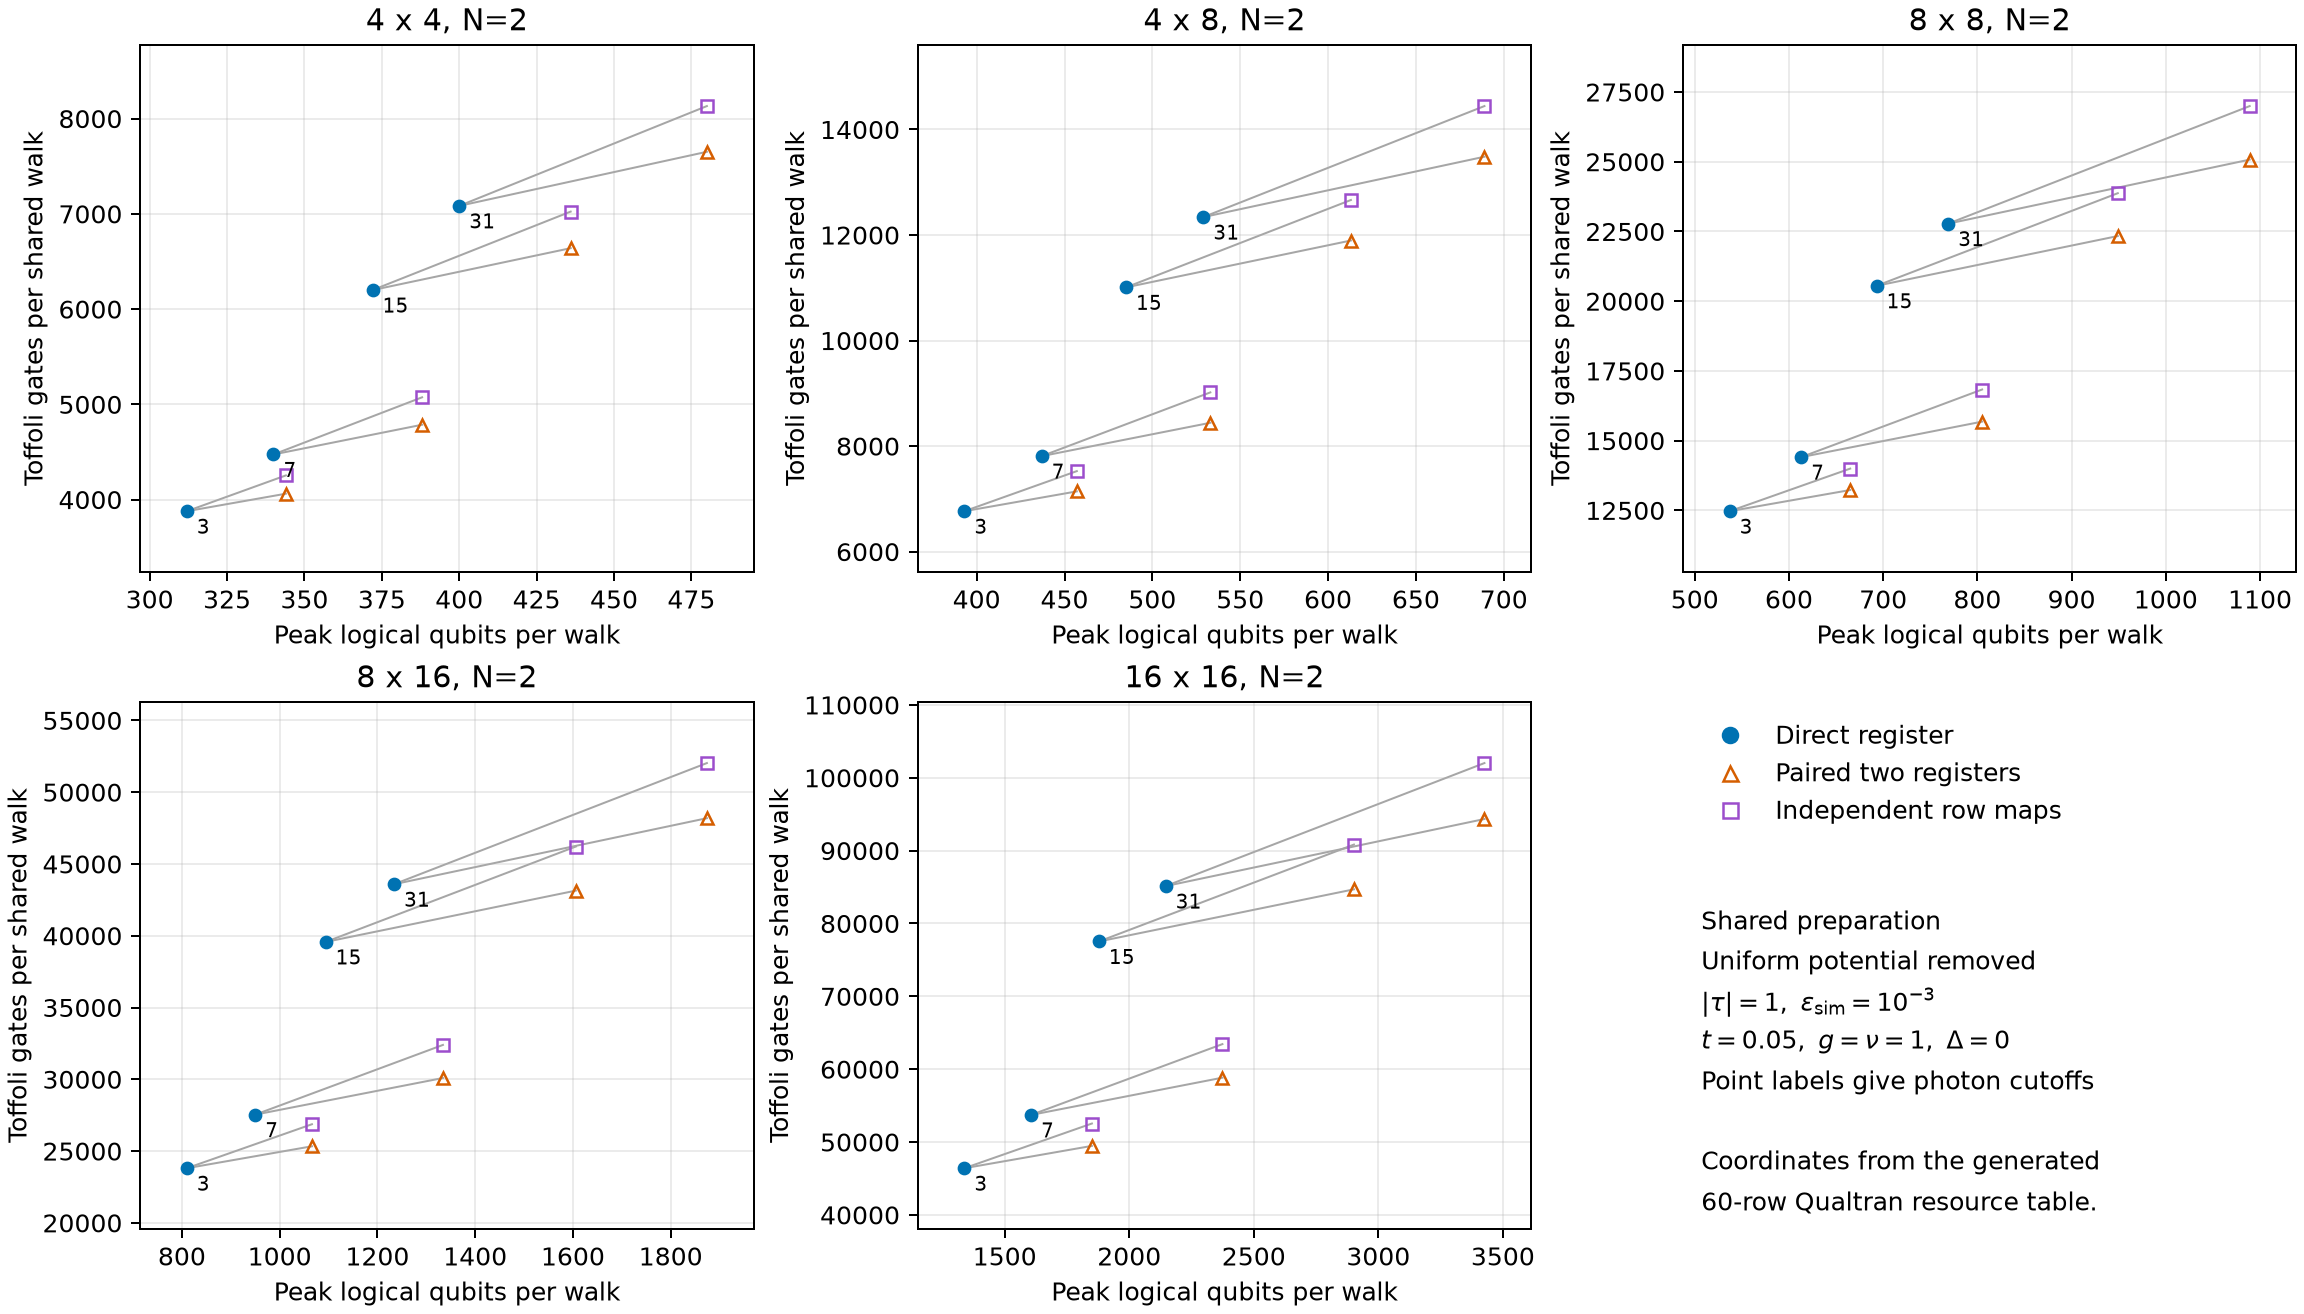

In [4]:
RECOMPILE_FIGURE7=False
figure7_table=resources.figure7_table(force=RECOMPILE_FIGURE7)
columns=['Lx','Ly','N','n_max','mode','b','B','coherent_ccx','peak_logical_qubits']
display(figure7_table[columns])
figure7_manifest=json.loads((resources.RESULTS/'figure7/manifest.json').read_text())
assert figure7_manifest['sources_sha256']==resources.source_hashes()
assert figure7_manifest['table_sha256']==hashlib.sha256((resources.RESULTS/'figure7_resource_table.csv').read_bytes()).hexdigest()
assert len(figure7_table)==60
assert not figure7_manifest['hard_coded_resource_points']
display(Image(filename=str(resources.RESULTS/'figure7_shared_walk_resources.png')))


## Tables III and IV: arithmetic subtotal reproduction and primitive audit

The analytical columns reproduce the printed fixed-precision ledger. Measured columns come from decomposed primitives, including complete forward/reverse XOR row oracles. The difference is attributable to destination-address upper-bound slack. This supports the arithmetic bounds, but is not a full coherent Hamiltonian encoding at those subtotals.

In [5]:
display(tables['III'])
display(tables['IV'][['L','branch','line_item','analytical','Toffoli_family','difference']])


,lattice,L,N,n_max,b,b_alias,direct_analytical,direct_qualtran_primitive_subtotal,direct_difference,sparse_analytical,...,sparse_difference,exact_match,direct_destination_bound_slack,sparse_destination_bound_slack,direct_upper_bound_with_DEST_slack,sparse_upper_bound_with_DEST_slack,primitive_ledger_bound_supported,alpha_TCL,alpha_TCL_0,full_block_encoding_verified
0,4 x 4,16,1,3,20,20,1016,996,-20,1222,...,-40,False,20,40,1016,1222,True,101,69,False
1,8 x 8,64,2,7,20,20,4186,4162,-24,5356,...,-48,False,24,48,4186,5356,True,1004,716,False
2,16 x 16,256,4,15,20,20,24854,24826,-28,31020,...,-56,False,28,56,24854,31020,True,9598,7166,False


,L,branch,line_item,analytical,Toffoli_family,difference
0,16,common,Hopping PREP and inverse,178,178,0
1,16,common,Local PREP and inverse,308,308,0
2,16,common,Local SELECT unary routing,127,127,0
3,16,common,Exchange increment and decrement,62,62,0
4,16,common,"Shared angle load, table, rotation",85,85,0
5,16,direct,Destination and inverse,24,4,-20
6,16,direct,Two occupation loads and inverses,120,120,0
7,16,direct,"Tables A, B and inverses",12,12,0
8,16,direct,Two phase-gradient rotations,38,38,0
9,16,direct,Direct shift plus carry/borrow chains,62,62,0


## Table VI: complete evolution schedule

All integer T/qubit columns match. Two printed decimal Bessel-tail bounds round downward; the `bound_rounded_up` column gives safe upward displays (2.3637e-8 and 2.9339e-8). This display issue changes neither degree nor gate count. Catalyst and initial-state preparation and measurement repetitions are excluded.

In [6]:
display(tables['VI'])
display(pd.read_csv(resources.RESULTS/'table_VI_differences.csv'))


,L,N,n_max,K,m,two_eta_bound,bound_rounded_up,T_U_direct,T_U_pair,Q_U_direct,Q_U_pair
0,16,1,3,62,22,2.086984e-08,2.0870e-08,3386082,3545794,320,352
1,64,2,7,485,25,2.363641e-08,2.3637e-08,99474508,108111388,639,831
2,256,4,15,4863,28,2.933821e-08,2.9339e-08,5718208314,6205675434,2428,3452


,L,N,n_max,K,m,T_U_direct,T_U_pair,Q_U_direct,Q_U_pair
0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0


## Appendix H: reported versus compiled per-channel counts

In [7]:
display(tables['H'])
assert not tables['H'].filter(like='difference').to_numpy().any()
print('Dilation-remainder qualification retained; this comparison verifies circuit accounting.')


,channel,reported_T_step,qualtran_T_step,difference_T,difference_CJ,difference_walk,reported_qubits,qualtran_qubits,difference_qubits
0,photon_loss,429786,429786,0,0,0,434,434,0
1,atomic_loss,406602,406602,0,0,0,434,434,0
2,dephasing,406098,406098,0,0,0,434,434,0


Dilation-remainder qualification retained; this comparison verifies circuit accounting.


## Table VII-style open-family extension (not a printed manuscript table)

In [8]:
display(tables['VII_style'])
manifest=json.loads((resources.RESULTS/'manifest.json').read_text())
assert manifest['sources_sha256']==resources.source_hashes()
print('Verified consolidated source hashes:',len(manifest['sources_sha256']))


,lattice,Lx,Ly,L,N,n_max,b,B,K,m,mean_T_step,worst_T_step,mean_T_run,worst_T_run,N_shot,N_step,total_mean_T,peak_logical_qubits
0,4x4,4,4,16,1,3,33,24,6,48,423990.0,429786,1.067006e+14,108159188336640,1794879,251658240,1.915146e+20,434
1,4x4,4,4,16,2,3,34,25,6,49,442293.6,451836,1.739169e+14,177669144576000,1794879,393216000,3.121598e+20,460
2,4x4,4,4,16,4,3,34,26,6,50,560550.0,574182,4.320178e+14,442523996651520,1794879,770703360,7.754196e+20,502
3,4x8,4,8,32,1,3,35,25,6,50,655914.0,662046,6.602647e+14,666437324636160,1936835,1006632960,1.278824e+21,505
4,4x8,4,8,32,2,3,35,26,6,51,687724.8,697536,1.081698e+15,1097129263104000,1936835,1572864000,2.095070e+21,543
5,4x8,4,8,32,4,3,36,27,6,52,926442.0,940842,2.856048e+15,2900440362516480,1936835,3082813440,5.531693e+21,621
6,8x8,8,8,64,1,3,36,26,6,52,1105734.0,1112034,4.452273e+15,4477640308162560,2078792,4026531840,9.255350e+21,619
7,8x8,8,8,64,2,3,36,27,6,53,1169700.0,1179780,7.359116e+15,7422533959680000,2078792,6291456000,1.529807e+22,689
8,8x8,8,8,64,4,3,37,28,6,54,1644846.0,1659630,2.028301e+16,20465318677708800,2078792,12331253760,4.216417e+22,831


Verified consolidated source hashes: 3
